In [ ]:
import pandas as pd

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
df = pd.read_csv("final_orders.csv.csv")

df.head()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2120 entries, 0 to 2119
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       2120 non-null   object 
 1   Order Date     2120 non-null   object 
 2   Ship Date      2120 non-null   object 
 3   Ship Mode      2120 non-null   object 
 4   Customer ID    2120 non-null   object 
 5   Customer Name  2120 non-null   object 
 6   Segment        2120 non-null   object 
 7   Country        2120 non-null   object 
 8   City           2120 non-null   object 
 9   State          2120 non-null   object 
 10  Postal Code    2120 non-null   int64  
 11  Region         2120 non-null   object 
 12  Product ID     2120 non-null   object 
 13  Category       2120 non-null   object 
 14  Sub-Category   2120 non-null   object 
 15  Product Name   2120 non-null   object 
 16  Sales          2120 non-null   float64
 17  Quantity       2120 non-null   int64  
 18  Discount

###Что мы видим из df.info():
###2120 строк
###20 колонок
###пропусков нет: везде 2120 non-null
###Sales → float64
###Quantity → int64
###Discount → float64
###Profit → float64
###Order Date и Ship Date сейчас object (нам это не надо) — ###их как раз надо #перевести в datetime

In [ ]:
df.columns

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
       'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df["month"] = df["Order Date"].dt.month
df["year"] = df["Order Date"].dt.year

In [ ]:
df[["Order Date", "Ship Date", "month", "year"]].head()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2120 entries, 0 to 2119
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       2120 non-null   object        
 1   Order Date     2120 non-null   datetime64[ns]
 2   Ship Date      2120 non-null   datetime64[ns]
 3   Ship Mode      2120 non-null   object        
 4   Customer ID    2120 non-null   object        
 5   Customer Name  2120 non-null   object        
 6   Segment        2120 non-null   object        
 7   Country        2120 non-null   object        
 8   City           2120 non-null   object        
 9   State          2120 non-null   object        
 10  Postal Code    2120 non-null   int64         
 11  Region         2120 non-null   object        
 12  Product ID     2120 non-null   object        
 13  Category       2120 non-null   object        
 14  Sub-Category   2120 non-null   object        
 15  Product Name   2120 n

###Теперь переходим к EDA.По заданию сначала надо построить распределения:Sales Profit Discount

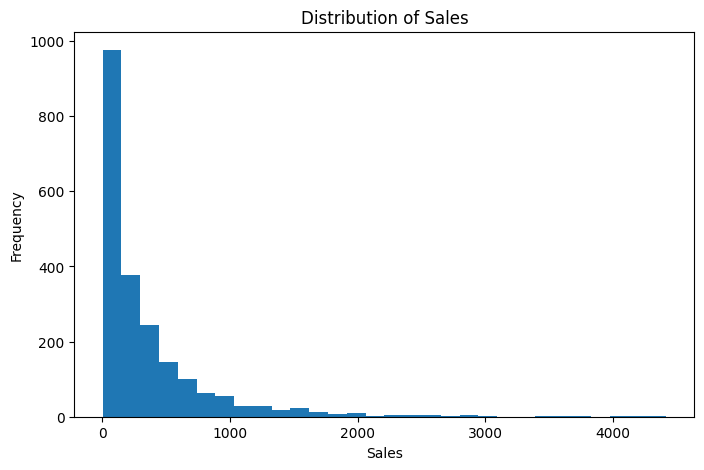

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=30)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

###plt.hist() — строим гистограмму;Sales — что анализируем;bins=30 — делим значения продаж на 30 интервалов;по X — размер продажи;по Y — сколько таких продаж встречается.

###Вывод: распределение продаж сильно скошено вправо. Большинство транзакций имеют относительно небольшую сумму продаж, а крупные продажи встречаются редко. Есть отдельные высокие значения, которые можно считать выбросами или просто редкими крупными заказами.

###Теперь строим распределение Profit.

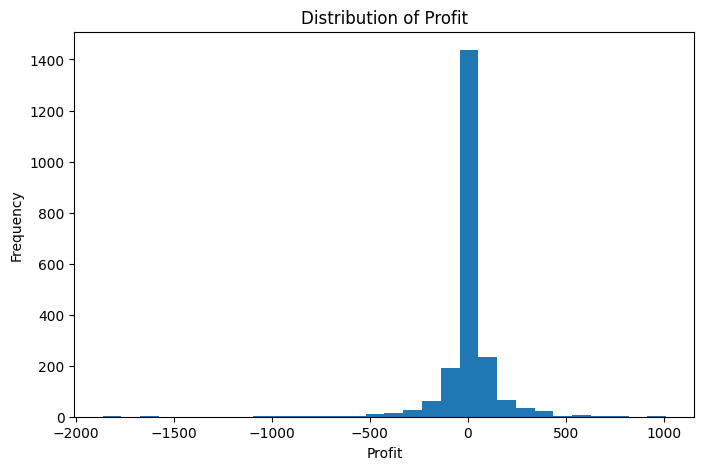

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["Profit"], bins=30)
plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

###Вывод по Profit:Большинство значений прибыли сосредоточено около 0.Есть как прибыльные, так и убыточные продажи.Видны редкие сильные выбросы в обе стороны.Убыточные выбросы более экстремальные: примерно до -1900, тогда как положительные - примерно до +1000

### строим распределение Discount

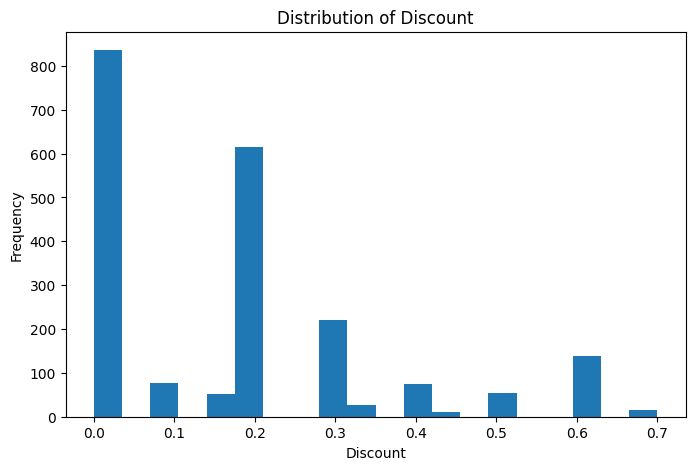

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["Discount"], bins=20)
plt.title("Distribution of Discount")
plt.xlabel("Discount")
plt.ylabel("Frequency")
plt.show()

###Вывод по скидкам:чаще всего продажи идут без скидки;самый распространённый ненулевой уровень скидки - примерно 20%;дальше заметны уровни около 30%, 40%, 50-60%;скидки распределены не непрерывно, а идут по фиксированным уровням.

###Теперь переходим к следующему пункту задания:

###«Исследуйте зависимости между скидкой и прибылью.»

###Делаем scatter plot.

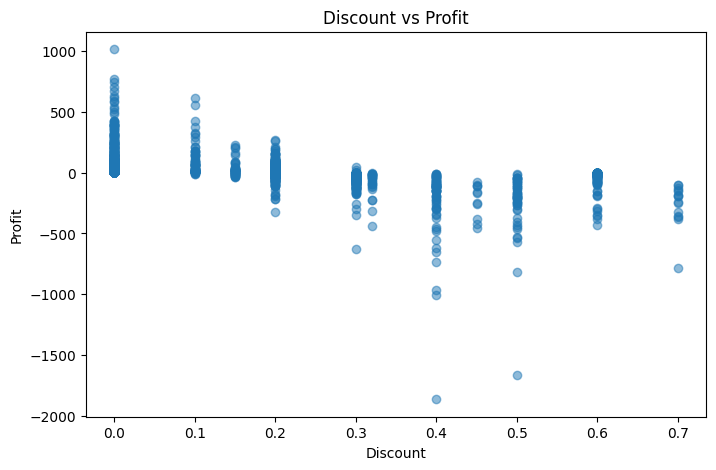

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Discount"], df["Profit"], alpha=0.5)
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

###Вывод по Discount → Profit:
###при скидке 0–10% много прибыльных продаж;
###примерно с 20–30% прибыль заметно снижается;
###при 40–70% большинство наблюдений уже около нуля или в минусе;
###самые сильные убытки тоже встречаются именно при больших скидках.

###То есть связь явно отрицательная: чем выше скидка, тем ниже прибыль.

##Чтобы не опираться только на картинку, ещё посчитаем коэффициент корреляции

In [ ]:
df[["Discount", "Profit"]].corr()

,Discount,Profit
Discount,1.000000,-0.483778
Profit,-0.483778,1.000000


###Корреляция получилась −0.484.
###Это значит:
###связь между Discount и Profit отрицательная;
###по силе она умеренная;
###при увеличении скидки прибыль в среднем снижается.

###Но важный момент для защиты: корреляция не доказывает причинность. Она показывает связь, а не гарантирует, что только скидка сама по себе вызывает снижение прибыли.

##Переходим к Linear Regression

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [ ]:
X = df[["Sales", "Discount", "Quantity"]]
y = df["Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

###from sklearn.model_selection import train_test_split -Это импорт функции, которая делит данные на две части: train и test
###from sklearn.linear_model import LinearRegression - Это импорт самой модели линейной регрессии
###Я использую Linear Regression, потому что по заданию нужно предсказывать числовую переменную Profit по Sales, Discount и Quantity
###Идея модели примерно такая:Profit = b0 + b1 * Sales + b2 * Discount + b3 * Quantity
###То есть модель ищет коэффициенты, которые лучше всего описывают связь признаков с прибылью.
###from sklearn.metrics import r2_score, mean_absolute_error - Это метрики для проверки качества модели
###R²:Показывает, какую долю вариации Profit может объяснить модель.

###Например, если R² = 0.50, это значит, что модель объясняет примерно 50% изменчивости Profit.

###MAE:Mean Absolute Error показывает среднюю абсолютную ошибку прогноза в тех же единицах, что и Profit.

###То есть если MAE = 50, модель в среднем ошибается примерно на 50 единиц прибыли.

###X = df[["Sales", "Discount", "Quantity"]] y = df["Profit"]
###X — признаки, то есть данные, по которым модель делает прогноз.

###У нас: Sales Discount Quantity

###y — целевая переменная, которую хотим предсказать: Profit
###X_train, X_test, y_train, y_test = train_test_split(    X, y, test_size=0.2, random_state=42)
###test_size=0.2 означает:80% данных используются для обучения модели, 20% — для проверки качества.

###У нас всего 2120 строк, поэтому примерно:1696 — train и 424 — test

###random_state=42:Это фиксирует случайное разделение, чтобы при повторном запуске я получал одинаковые train и test наборы
###42 это общепринятое фиксированное seed-значение

###model = LinearRegression() - Здесь модель обучается на тренировочных данных. Она ищет такие коэффициенты при Sales, Discount и Quantity, которые минимизируют ошибку предсказания Profit.

###LinearRegression() - это не результат прогноза.
###Это просто подтверждение, что объект модели успешно обучен

###Summary:Я выбрал Profit как целевую переменную и Sales, Discount и Quantity как признаки. Затем разделил данные на обучающую и тестовую выборки в пропорции 80/20. На обучающей выборке обучил модель Linear Regression. Следующим шагом я проверяю коэффициенты признаков и качество модели на тестовой выборке.

In [ ]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,Sales,0.050183
1,Discount,-344.742204
2,Quantity,0.778528


###Что здесь происходит: X.columns берёт названия признаков: Sales, Discount, Quantity.  model.coef_ берёт коэффициенты, которые модель нашла после обучения.  pd.DataFrame(...) собирает это в понятную таблицу.  coefficients выводит эту таблицу.
### Это необходимо чтобы интерпретировать влияние каждого признака на Profit и понять направление этого влияния.

###Что это значит.
###Sales = 0.050183 Если Sales увеличивается на 1 единицу, то прогнозируемый Profit в среднем увеличивается примерно на 0.05, при прочих равных.
###Discount = -344.742204 Вот это самый важный коэффициент. Он отрицательный.
###Если Discount увеличивается на 1.0, то прогнозируемый Profit уменьшается примерно на 344.74.
###Но у нас Discount хранится как доля:0.1 = 10%; 0.2 = 20%;0.3 = 30%
###Поэтому увеличение скидки на 10 процентных пунктов, то есть на 0.1, связано примерно со снижением прогнозируемой прибыли на: 344.74 × 0.1 ≈ 34.47
###То есть примерно на 34.5 единицы прибыли, при прочих равных.
###Quantity = 0.778528 Если количество товара увеличивается на 1 единицу, прогнозируемая прибыль увеличивается примерно на 0.78, при прочих равных.

In [ ]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("R²:", r2)
print("MAE:", mae)

R²: 0.18785551468647066
MAE: 67.06669671631263


###Комментарий к коду: model.predict(X_test) — модель делает прогноз Profit на тестовых данных. R² показывает, какую часть вариации Profit объясняет модель. MAE показывает среднюю абсолютную ошибку прогноза.
###y_pred = model.predict(X_test) - модель делает прогноз Profit для тестовой выборки. r2 = r2_score(y_test, y_pred) - сравниваем реальные значения Profit с прогнозами и считаем R².
### mae = mean_absolute_error(y_test, y_pred) - считаем среднюю абсолютную ошибку прогноза.

###Интерпретация результатов: R² = 0.188; MAE = 67.07
###Это значит, что модель получилась не очень сильная, но  она базовая и имеет ограниченную точность, но позволяет оценить направление влияния Sales, Discount, Quantity на Profit и главное — мы можем правильно её интерпретировать.
###R² = 0.188 означает:Модель объясняет примерно 18.8% изменчивости Profit с помощью Sales, Discount и Quantity.То есть большая часть прибыли зависит ещё и от других факторов, которых в модели нет: конкретного товара, себестоимости, региона, подкатегории, типа клиента и т.д.
###MAE = 67.07 означает:В среднем прогноз модели отличается от реального Profit примерно на 67 единиц.
##Summary:Модель имеет R² около 0.19, то есть объясняет примерно 19% вариации прибыли. MAE около 67 означает, что средняя абсолютная ошибка прогноза составляет примерно 67 единиц прибыли. Поэтому модель показывает общие зависимости, но её прогнозная точность ограничена.

In [ ]:
df["profit_pred"] = model.predict(
    df[["Sales", "Discount", "Quantity"]]
)

df[["Profit", "profit_pred"]].head()

###Комментарий к коду:берём все строки таблицы;для каждой строки модель прогнозирует Profit;результат записываем в новую колонку profit_pred;затем выводим реальные и прогнозные значения рядом для проверки.
###profit_pred уже создан правильно И важный момент: то, что реальные Profit и profit_pred заметно отличаются, нормально. Мы уже видели, что R² ≈ 0.19, поэтому модель ловит только общую зависимость, а не идеально угадывает каждую строку

In [ ]:
df.to_csv("forecast.csv", index=False)

###Комментарий к коду:df.to_csv(...) — сохраняет весь DataFrame в CSV;"forecast.csv" — имя итогового файла;index=False — не сохраняем служебный pandas-индекс отдельной колонкой

In [ ]:
from google.colab import files

files.download("forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###После обучения модели я применил её ко всей таблице и создал новую колонку profit_pred с прогнозируемой прибылью для каждой строки. Затем сохранил итоговую таблицу в forecast.csv для последующей загрузки в Power BI.